# 05 — Plume Pathway Ensemble (ERA5 kinematic trajectories)

**Biobío wildfire, 18 January 2026.** A 500-member Monte-Carlo ensemble of
ERA5-driven isobaric trajectories, sampled from observation-informed priors
(injection pressure from AER_LH, source from FRP-weighted MODIS, launch hour
uniform over the fire-active window).

**Scope — this notebook answers two questions only:**
1. **Transport pathway** — the corridor probability map, validated against the
   TROPOMI AER_AI plume on +1…+4 d.
2. An **emission-independent plume mask** used downstream to exclude
   plume-contaminated pixels from the emission-retrieval background window.

It does **not** measure dispersion/extent or detectability — those are handled
by the observed columns and the HYSPLIT forward run (notebook 06). The corridor
width here is *release-parameter* spread, not physical mixing.

> Limitations: isobaric (vertical motion neglected; release height pinned from
> AER_LH); a single ERA5 realization drives every member, so the corridor
> reflects release uncertainty only, not transport/wind uncertainty.


In [1]:
from __future__ import annotations
import os, json
from datetime import datetime
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely

# ── Locate project root regardless of kernel CWD ─────────────────────────────
_here = Path('.').resolve()
ROOT = next((p for p in [_here] + list(_here.parents)
             if (p / 'data').exists() and (p / 'src').exists()), None)
if ROOT is None:
    raise RuntimeError(f'Cannot locate project root from {_here}.')
os.chdir(ROOT)
print(f'Project root: {ROOT}')

from src.data_helpers import load_aer_ai, load_aer_lh
from src.fire_clustering import load_modis_csv
from src.wind_helpers import _haversine_km
from src import trajectory as T
from src import plume_helpers as ph

DATA_DIR = ROOT / 'data'
OUT_DIR  = ROOT / 'outputs' / 'pathway'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Fire centre (dominant MODIS cluster, consistent with retrievals) ─────────
FIRE_LAT, FIRE_LON = -37.5484, -72.5545
FIRE_DATE = '2026-01-18'

# ── Monte-Carlo parameters (all explicit, logged) ────────────────────────────
N_SAMPLES        = 500
SEED             = 42
LAUNCH_HOUR_MIN  = 10.0          # UTC, fire-active window
LAUNCH_HOUR_MAX  = 22.0
RUN_HOURS        = 96
DT_S             = 1800          # 30-min RK4 step

# ── Prior-construction parameters ────────────────────────────────────────────
# Fallback AER_AI threshold for dates with no saved plume boundary (see
# load_ai_with_boundary below); dates with a boundary use its own threshold.
AI_THRESHOLD          = 2.0      # AER_AI plume threshold
PRESSURE_MATCH_R_KM   = 450.0    # AER_LH match radius (== retrieval extraction radius)
LOCAL_FIRE_RADIUS_KM  = 200.0    # spatial-KDE locality filter

# ── Corridor grid + background-exclusion mask ────────────────────────────────
LAT_MIN, LAT_MAX = -45.0, -17.0
LON_MIN, LON_MAX = -90.0, -65.0
GRID_RES         = 0.25
MASK_THRESHOLD   = 0.05          # cells visited by >=5% of members -> plume mask

# ── ERA5 domain (clip for sampling) ──────────────────────────────────────────
ERA5_LAT = (-66.75, -7.0)
ERA5_LON = (-103.0, -43.25)

# ── Pathway-validation overpasses (offset days with AER_AI) ──────────────────
VALIDATION = [
    {'folder': '0119', 'offset': 1, 'age_h': 24.0},
    {'folder': '0120', 'offset': 2, 'age_h': 48.0},
    {'folder': '0121', 'offset': 3, 'age_h': 72.0},
    {'folder': '0122', 'offset': 4, 'age_h': 96.0},
]
print('Config loaded.')

Project root: /Users/maperezc/Downloads/wildfires
Config loaded.


In [2]:
# ── Load observation inputs ──────────────────────────────────────────────────
def load_and_concat(paths, loader, **kwargs):
    """Concatenate a loader's output across multiple L2 overpass files."""
    chunks = defaultdict(list)
    scalars = {}
    for pth in paths:
        pth = Path(pth)
        data = loader(pth, **kwargs)
        if data is None:
            continue  # skip orbits with no valid pixels in the ROI
        for k, v in data.items():
            if isinstance(v, np.ndarray):
                chunks[k].append(v)
            else:
                scalars[k] = v
    out = {k: np.concatenate(v) for k, v in chunks.items()}
    out.update(scalars)
    return out


def load_ai_with_boundary(folder, **roi_kwargs):
    """Load+concat all AER_AI overpasses for `folder`, clipped to its saved
    plume boundary when one exists (data/{folder}/plume_boundary.geojson).

    Falls back to the raw module-level AI_THRESHOLD with NO spatial gate for
    dates without a boundary file (AI=2.0 doesn't produce a consistent plume
    on every date — only 0118/0119 have hand-reviewed boundaries so far).
    Returns (ai_data, threshold_used, boundary_used: bool).
    """
    paths = sorted((DATA_DIR / folder).glob('S5P_OFFL_L2__AER_AI_2026*.nc'))
    if not paths:
        return None, None, False
    ai_data = load_and_concat(paths, load_aer_ai, **roi_kwargs)
    boundary_path = DATA_DIR / folder / 'plume_boundary.geojson'
    if boundary_path.is_file():
        boundary = ph.load_plume_boundary(boundary_path)
        in_boundary = shapely.contains_xy(boundary.boundary, ai_data['lon'], ai_data['lat'])
        ai_data['ai'] = np.where(in_boundary, ai_data['ai'],
                                  np.minimum(ai_data['ai'], boundary.threshold - 1e-3))
        return ai_data, boundary.threshold, True
    print(f'  [{folder}] no plume_boundary.geojson — using raw AI > {AI_THRESHOLD} '
          f'with no spatial gate (ungated).')
    return ai_data, AI_THRESHOLD, False


roi_kwargs_0118 = dict(lat_min=-47, lat_max=-26, lon_min=-82, lon_max=-62, qa_threshold=50)

ai, AI_THRESHOLD_0118, _boundary_used_0118 = load_ai_with_boundary('0118', **roi_kwargs_0118)
alh = load_and_concat(sorted((DATA_DIR / '0118').glob('S5P_OFFL_L2__AER_LH_2026*.nc')),
                      load_aer_lh, **roi_kwargs_0118)
fires = load_modis_csv(DATA_DIR / 'fire_nrt_M-C61_723973.csv',
                       pd.Timestamp(FIRE_DATE), pd.Timestamp(FIRE_DATE),
                       lat_min=ERA5_LAT[0], lat_max=ERA5_LAT[1],
                       lon_min=ERA5_LON[0], lon_max=ERA5_LON[1],
                       min_confidence=75, daytime_only=True, satellite='Aqua')
print(f'AER_AI px: {len(ai["ai"]):,} | AER_LH px: {len(alh["alh_pres"]):,} | MODIS Aqua px: {len(fires):,}  '
      f'(boundary used for 0118: {_boundary_used_0118}, threshold={AI_THRESHOLD_0118})')

AER_AI px: 157,805 | AER_LH px: 26,695 | MODIS Aqua px: 172  (boundary used for 0118: True, threshold=2.0)


In [3]:
# ── Build observation-informed priors ────────────────────────────────────────
kde_pres, valid_hpa, p_stats = T.build_pressure_kde(
    ai, alh, FIRE_LAT, FIRE_LON, ai_threshold=AI_THRESHOLD_0118, radius_km=PRESSURE_MATCH_R_KM)
print(f'Injection-pressure KDE: n={p_stats["n"]}  median={p_stats["mean"]:.0f} hPa  '
      f'IQR={p_stats["iqr"]:.0f}  p05/p95={p_stats["p05"]:.0f}/{p_stats["p95"]:.0f}')

kde_sp, s_info = T.build_spatial_frp_kde(
    fires, FIRE_LAT, FIRE_LON, local_radius_km=LOCAL_FIRE_RADIUS_KM)
print(f'Spatial FRP KDE: n={s_info["n_pixels"]}  '
      f'centroid=({s_info["frp_centroid_lat"]:.3f}, {s_info["frp_centroid_lon"]:.3f})  '
      f'FRP={s_info["frp_sum_mw"]:.0f} MW')

Injection-pressure KDE: n=99  median=883 hPa  IQR=73  p05/p95=768/969
Spatial FRP KDE: n=146  centroid=(-37.061, -72.749)  FRP=34202 MW


In [4]:
# ── ERA5 wind field, sample priors, run the ensemble ─────────────────────────
wf = T.ERA5WindField(DATA_DIR / 'ERA5_winds_pressure_levels.nc')
params = T.sample_release_params(
    kde_pres, kde_sp, n_samples=N_SAMPLES, seed=SEED,
    launch_hour_min=LAUNCH_HOUR_MIN, launch_hour_max=LAUNCH_HOUR_MAX,
    pres_clip=(wf.pres_min, wf.pres_max), lat_clip=ERA5_LAT, lon_clip=ERA5_LON)
print(f'Sampled {N_SAMPLES} members  (clipped: pres={params["n_clipped_pres"]}, '
      f'spatial={params["n_clipped_spatial"]})')

ensemble = T.run_ensemble(wf, params, datetime(2026, 1, 18), RUN_HOURS, DT_S)
n_complete = sum(1 for t in ensemble if not np.isnan(t['lat'][-1]))
print(f'Ensemble: {len(ensemble)} members, {n_complete} complete to +{RUN_HOURS} h')

Sampled 500 members  (clipped: pres=25, spatial=0)
Ensemble: 500 members, 500 complete to +96 h


In [5]:
# ── Corridor probability + emission-independent plume mask ────────────────────
lat_edges = np.arange(LAT_MIN, LAT_MAX + GRID_RES, GRID_RES)
lon_edges = np.arange(LON_MIN, LON_MAX + GRID_RES, GRID_RES)
lat_ctrs  = 0.5 * (lat_edges[:-1] + lat_edges[1:])
lon_ctrs  = 0.5 * (lon_edges[:-1] + lon_edges[1:])

corridor_prob = T.corridor_probability(ensemble, lat_edges, lon_edges)
plume_mask = corridor_prob >= MASK_THRESHOLD

assert corridor_prob.max() <= 1.0 and corridor_prob.min() >= 0.0
assert plume_mask.sum() > 0, 'Empty plume mask — check MASK_THRESHOLD.'
i_src = np.clip(np.searchsorted(lat_edges, FIRE_LAT, side='right') - 1, 0, len(lat_ctrs) - 1)
j_src = np.clip(np.searchsorted(lon_edges, FIRE_LON, side='right') - 1, 0, len(lon_ctrs) - 1)
src_in_mask = bool(plume_mask[i_src, j_src])

cell_area_km2 = (GRID_RES * 111.0) ** 2 * np.cos(np.radians(lat_ctrs)).mean()
print(f'Corridor: peak p={corridor_prob.max():.1%}  '
      f'cells>10%={int((corridor_prob>0.1).sum())}  cells>25%={int((corridor_prob>0.25).sum())}')
print(f'Plume mask (p>={MASK_THRESHOLD:.0%}): {int(plume_mask.sum())} cells '
      f'(~{plume_mask.sum()*cell_area_km2:,.0f} km2) | fire source in mask: {src_in_mask}')

# ── Save for downstream background exclusion ─────────────────────────────────
np.save(OUT_DIR / 'corridor_prob.npy', corridor_prob)
np.save(OUT_DIR / 'lat_edges.npy', lat_edges)
np.save(OUT_DIR / 'lon_edges.npy', lon_edges)
mask_ii, mask_jj = np.where(plume_mask)
pd.DataFrame({'lat_center': lat_ctrs[mask_ii], 'lon_center': lon_ctrs[mask_jj],
              'probability': corridor_prob[mask_ii, mask_jj]}).to_csv(
    OUT_DIR / 'plume_mask.csv', index=False, float_format='%.4f')
print(f'Saved corridor_prob.npy, lat/lon_edges.npy, plume_mask.csv -> {OUT_DIR}')

Corridor: peak p=42.8%  cells>10%=154  cells>25%=11
Plume mask (p>=5%): 410 cells (~267,945 km2) | fire source in mask: True
Saved corridor_prob.npy, lat/lon_edges.npy, plume_mask.csv -> /Users/maperezc/Downloads/wildfires/outputs/pathway


In [6]:
# ── Pathway validation vs TROPOMI AER_AI on +1..+4 d ─────────────────────────
# The fire is still active on +1..+4 d, so each day's AER_AI mixes fresh
# near-source smoke with the aged transported plume; a single plume centroid is
# therefore confounded. We instead use two emission-robust metrics:
#   (1) leading-edge reach  — observed AER_AI vs ensemble (does transport carry
#       the plume the observed distance?);
#   (2) AER_AI-in-corridor fraction — share of observed plume pixels that fall
#       inside the corridor mask (does the corridor contain the observed plume?).
#
# Uses the plume boundary (data/{folder}/plume_boundary.geojson) where one
# exists (0119); other validation dates (0120-0122) fall back to the raw
# AI > AI_THRESHOLD mask with no spatial gate — see load_ai_with_boundary's
# printed warning above/below for which dates are ungated.
def aai_plume(folder):
    roi_kwargs = dict(lat_min=LAT_MIN, lat_max=LAT_MAX, lon_min=LON_MIN, lon_max=LON_MAX, qa_threshold=50)
    a, threshold, boundary_used = load_ai_with_boundary(folder, **roi_kwargs)
    if a is None:
        return None
    m = (a['ai'] > threshold) & np.isfinite(a['ai'])
    if m.sum() < 5:
        return None
    return dict(lat=a['lat'][m], lon=a['lon'][m], n=int(m.sum()), boundary_used=boundary_used)

def in_corridor(lat, lon):
    # Out-of-grid pixels are outside the corridor by definition — do NOT clamp
    # them into the border cells (clamping inherits the border cell's mask value).
    il = np.searchsorted(lat_edges, lat, side='right') - 1
    jl = np.searchsorted(lon_edges, lon, side='right') - 1
    ok = (il >= 0) & (il < len(lat_ctrs)) & (jl >= 0) & (jl < len(lon_ctrs))
    inside = np.zeros(np.shape(lat), dtype=bool)
    inside[ok] = plume_mask[il[ok], jl[ok]]
    return inside

def ens_leading_edge(age_h):
    dmax = []
    for t in ensemble:
        k = int(np.argmin(np.abs(t['time_h'] - age_h)))
        if np.isfinite(t['lat'][k]):
            dmax.append(_haversine_km(FIRE_LAT, FIRE_LON,
                                      np.array([t['lat'][k]]), np.array([t['lon'][k]]))[0])
    if not dmax:
        return np.nan, np.nan
    return float(np.percentile(dmax, 90)), float(np.max(dmax))

val_rows = []
for v in VALIDATION:
    obs = aai_plume(v['folder'])
    p90, pmax = ens_leading_edge(v['age_h'])
    if obs is None:
        val_rows.append({'offset_d': v['offset'], 'age_h': v['age_h'], 'note': 'no AER_AI plume'})
        continue
    d_obs = _haversine_km(FIRE_LAT, FIRE_LON, obs['lat'], obs['lon'])
    val_rows.append({'offset_d': v['offset'], 'age_h': v['age_h'], 'n_aai_plume': obs['n'],
                     'boundary_used':           obs['boundary_used'],
                     'obs_leading_edge_km':     round(float(d_obs.max()), 0),
                     'ens_leading_edge_km_p90': round(p90, 0),
                     'ens_leading_edge_km_max': round(pmax, 0),
                     'aai_in_corridor_frac':    round(float(in_corridor(obs['lat'], obs['lon']).mean()), 2)})
val_df = pd.DataFrame(val_rows)
print(val_df.to_string(index=False))
val_df.to_csv(OUT_DIR / 'pathway_validation.csv', index=False)

  [0120] no plume_boundary.geojson — using raw AI > 2.0 with no spatial gate (ungated).
  [0121] no plume_boundary.geojson — using raw AI > 2.0 with no spatial gate (ungated).
 offset_d  age_h  n_aai_plume boundary_used  obs_leading_edge_km  ens_leading_edge_km_p90  ens_leading_edge_km_max  aai_in_corridor_frac            note
        1   24.0       1907.0          True               1059.0                    897.0                   1040.0                  0.39             NaN
        2   48.0       1620.0         False               2289.0                   1418.0                   1588.0                  0.39             NaN
        3   72.0        201.0         False               2233.0                   1902.0                   2077.0                  0.03             NaN
        4   96.0          NaN           NaN                  NaN                      NaN                      NaN                   NaN no AER_AI plume


  [0120] no plume_boundary.geojson — using raw AI > 2.0 with no spatial gate (ungated).
  [0121] no plume_boundary.geojson — using raw AI > 2.0 with no spatial gate (ungated).
Saved corridor_map.png -> /Users/maperezc/Downloads/wildfires/outputs/pathway


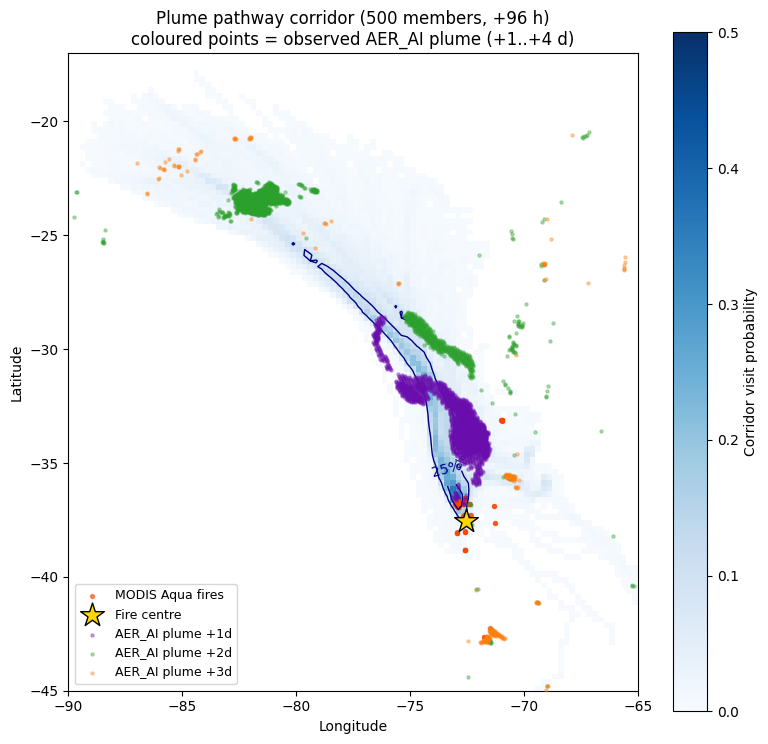

In [7]:
# ── Figure 1: corridor probability + MODIS fires ─────────────────────────────
LON2D, LAT2D = np.meshgrid(lon_ctrs, lat_ctrs)
fig, ax = plt.subplots(figsize=(8, 10))
pm = ax.pcolormesh(lon_edges, lat_edges, np.where(corridor_prob > 0, corridor_prob, np.nan),
                   cmap='Blues', vmin=0, vmax=max(0.5, corridor_prob.max()), shading='flat')
plt.colorbar(pm, ax=ax, shrink=0.7, label='Corridor visit probability')
cs = ax.contour(LON2D, LAT2D, corridor_prob, levels=[0.1, 0.25], colors='navy', linewidths=1.0)
ax.clabel(cs, fmt=lambda x: f'{x:.0%}')
ax.scatter(fires['longitude'], fires['latitude'], s=8, c='orangered', alpha=0.6, label='MODIS Aqua fires')
ax.scatter(FIRE_LON, FIRE_LAT, marker='*', s=320, c='gold', edgecolors='k', zorder=10, label='Fire centre')
_dcols = ['#6a0dad', '#2ca02c', '#ff7f0e', '#d62728']
for v, c in zip(VALIDATION, _dcols):
    obs = aai_plume(v['folder'])
    if obs:
        ax.scatter(obs['lon'], obs['lat'], s=5, c=c, alpha=0.35, zorder=7,
                   label=f"AER_AI plume +{v['offset']}d")
ax.set_xlim(LON_MIN, LON_MAX); ax.set_ylim(LAT_MIN, LAT_MAX); ax.set_aspect('equal')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title(f'Plume pathway corridor ({N_SAMPLES} members, +{RUN_HOURS} h)\n'
             f'coloured points = observed AER_AI plume (+1..+4 d)')
ax.legend(loc='lower left', fontsize=9)
fig.tight_layout(); fig.savefig(OUT_DIR / 'corridor_map.png', dpi=140, bbox_inches='tight')
print(f'Saved corridor_map.png -> {OUT_DIR}')

## Summary

- The corridor is the **transport pathway** prior; its agreement with the
  observed AER_AI plume centroid on +1…+4 d is quantified in
  `pathway_validation.csv` (`centerline_offset_km`).
- `plume_mask.csv` / `corridor_prob.npy` are the **emission-independent**
  background-exclusion mask for the CO/NOₓ retrievals — independent of the
  emission magnitude because it depends only on transport.
- Dispersion/extent and detectability are deliberately **not** computed here.
